# 03 Evaluate: the main model and the baselines on the test quarters (used once)

**Purpose.** Answer the last part of the project question: how close does the chosen model come to the actual
spread over SOFR of newly originated loans in quarters it has never seen, compared with the simple pricing rules a
deal team could use? This is the final evaluation of the course template (`files/example_project_structure`,
`example_03_evaluate.ipynb`): it reads the predictions written by notebook 02 and computes every test metric.

**Rules (D45, D49, D51, D50).** This notebook fits no model. The main model was chosen and recorded on the
validation folds in notebook 02 (`output/tables/model_choice.csv`) before any test prediction was made; nothing here
changes that choice. The other candidates are shown on the test quarters for description only, because our
commitments ask for the test error of all models and baselines; choosing among them on these numbers would turn the
test quarters into validation data.

**Input.** `data/processed/predictions_test.csv` (22 candidates x 583 test loans, protocol D41: one fit per test
quarter t on loans up to t-2 filed before t), `predictions_validation.csv` (for the comparison with validation),
`predictions_robustness.csv`, `loans.csv` (test rows, for the syndicated-loan flag), `output/tables/model_choice.csv`.

**Output** (`output/tables/`, `output/figures/`):
- `test_headline.csv`: main model, both baselines and the reference on the test quarters (step 2).
- `test_by_quarter.csv` and `test_by_quarter.png`: MAE, share within 50 bps and mean error per test quarter (step 3).
- `test_bootstrap.csv`: 95% intervals for the MAE gap between the main model and each baseline (step 4).
- `test_by_family.csv`: errors by manager family (step 5).
- `test_all_candidates.csv`: every candidate, test against validation, descriptive only (step 6).
- `test_single_fit.csv`: the secondary protocol, one fit up to 2025Q1 (step 7).
- `test_sensitivity_robustness.csv`: without likely syndicated loans; all BDCs; refinancings included (step 8).

**Metrics (committed).** MAE in basis points (main), share of loans within plus or minus 50 bps, both overall, by
test quarter and by manager family. Mean error = actual minus predicted spread in bps: positive means the
prediction is too low (the sign used in D47 and D51).

## Step 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import modelling_helpers as mh  # noqa: E402

PROC = ROOT / "data" / "processed"
FIG = ROOT / "output" / "figures"
TAB = ROOT / "output" / "tables"
SEED = 42                       # used for the bootstrap in step 4
np.random.seed(SEED)

def metrics(d):
    """Committed metrics on a frame with y_true and y_pred (percentage points); errors in bps."""
    err = (d["y_true"] - d["y_pred"]) * 100
    return pd.Series({"n": len(d), "mae_bps": err.abs().mean(), "share_within_50bps": (err.abs() <= 50).mean(),
                      "mean_error_bps": err.mean()})

print("project folder:", ROOT.name, "| pandas", pd.__version__)

project folder: DSF_Project | pandas 3.1.1


## Step 1. Inputs and their checks

**What.** We read the test predictions of notebook 02, the validation predictions, the test rows of the working
dataset and the recorded main model.

**Why.** The metrics are only as good as the alignment of predictions and loans. Before computing any error we make
sure that every candidate predicts every test loan exactly once and that the actual spreads in the prediction file
are the ones in `loans.csv`.

**Check.** 22 candidates x 583 test loans, no duplicate (model, loan) pair; test quarters 2025Q3 to 2026Q2 only;
`y_true` equals `spread_pp` of `loans.csv`; the stored absolute error equals the recomputed one; the main model of
`model_choice.csv` and its single-fit variant are in the file.

In [2]:
test = pd.read_csv(PROC / "predictions_test.csv")
val = pd.read_csv(PROC / "predictions_validation.csv")
loans = pd.read_csv(PROC / "loans.csv")
test_loans = loans[loans["split"] == "test"].set_index("loan_id")
choice = pd.read_csv(TAB / "model_choice.csv")

MAIN = choice.loc[0, "main_model"]
SINGLE = MAIN + " [single fit to 2025Q1]"
B1, B2, REF = "Baseline 1: market median t-2", "Baseline 2: sector x size median", "Reference: training mean"
HEADLINE = [MAIN, B1, B2, REF]
QUARTERS = ["2025Q3", "2025Q4", "2026Q1", "2026Q2"]
print("main model (chosen on validation, D49/D51):", MAIN)
print("candidates in the test file:", test["model"].nunique(), "| test loans:", test["loan_id"].nunique())
print(test.groupby("quarter")["loan_id"].nunique().to_string())

# Check: every candidate predicts every test loan exactly once
assert test["model"].nunique() == 22 and not test.duplicated(["model", "loan_id"]).any()
assert (test.groupby("model")["loan_id"].nunique() == len(test_loans)).all() and len(test_loans) == 583
assert set(test["loan_id"]) == set(test_loans.index) and sorted(test["quarter"].unique()) == QUARTERS
# Check: actual spreads and stored errors agree with the working dataset
assert np.allclose(test["y_true"], test_loans.loc[test["loan_id"], "spread_pp"].to_numpy())
assert np.allclose(test["abs_error_bps"], (test["y_true"] - test["y_pred"]).abs() * 100, atol=1e-3)
assert all(m in set(test["model"]) for m in HEADLINE + [SINGLE])
assert test["y_pred"].between(1, 15).all()

main model (chosen on validation, D49/D51): Random forest (residual, revolver + delayed draw)
candidates in the test file: 22 | test loans: 583
quarter
2025Q3    164
2025Q4    149
2026Q1    147
2026Q2    123


## Step 2. Headline result: main model against the baselines

**What.** MAE, share within 50 bps and mean error over all 583 test loans for the main model, the two committed
baselines and the reference (training mean), next to the same metrics on the validation quarters.

**Why.** The project question is whether a model beats the simple pricing rules on quarters it has not seen. The
validation number of the main model is optimistic (about 20 variants were compared on the same four quarters,
`docs/model_report.md`, section 10); the test number is the honest one, and the difference shows how much optimism
there was.

**Check.** The pooled MAE equals the mean of the stored absolute errors; the validation MAE of the main model equals
the number recorded in `model_choice.csv`.

In [3]:
rows = []
for m in HEADLINE:
    t = metrics(test[test["model"] == m])
    v = metrics(val[val["model"] == m])
    rows.append({"model": m, "n_test": int(t["n"]), "test_mae_bps": t["mae_bps"],
                 "test_share_within_50bps": t["share_within_50bps"], "test_mean_error_bps": t["mean_error_bps"],
                 "validation_mae_bps": v["mae_bps"], "validation_share_within_50bps": v["share_within_50bps"]})
headline = pd.DataFrame(rows)
headline["test_minus_validation_mae_bps"] = headline["test_mae_bps"] - headline["validation_mae_bps"]
headline = headline.round({c: 1 for c in headline.columns if c.endswith("_bps")} | {
    "test_share_within_50bps": 3, "validation_share_within_50bps": 3})
headline.to_csv(TAB / "test_headline.csv", index=False)
print(headline.to_string(index=False))

# Check
for m in HEADLINE:
    assert abs(headline.set_index("model").loc[m, "test_mae_bps"]
               - test.loc[test["model"] == m, "abs_error_bps"].mean()) < 0.06
assert abs(headline.set_index("model").loc[MAIN, "validation_mae_bps"] - choice.loc[0, "validation_mae_bps"]) < 0.06

                                            model  n_test  test_mae_bps  test_share_within_50bps  test_mean_error_bps  validation_mae_bps  validation_share_within_50bps  test_minus_validation_mae_bps
Random forest (residual, revolver + delayed draw)     583          58.1                    0.554                 -1.7                54.9                          0.630                            3.2
                    Baseline 1: market median t-2     583          86.3                    0.503                -27.8                78.6                          0.584                            7.7
                 Baseline 2: sector x size median     583          79.9                    0.537                -24.0                98.3                          0.385                          -18.4
                         Reference: training mean     583          92.3                    0.451                -57.0                96.0                          0.409                           -3.7


## Step 3. Errors by test quarter

**What.** The three metrics for each of the four test quarters (2025Q3 to 2026Q2), for the main model, both
baselines and the reference, in a table and a figure.

**Why.** We committed to report performance by test quarter (lecturers' feedback 3): loans of the same quarter share
one market, so four quarters are four partly independent tests, not 583. The mean error shows whether the known
weakness of the main model (predicted too low in every validation quarter, +8 to +24 bps, D47) persists.

**Check.** Loans per quarter add up to 583; the loan-weighted average of the quarter MAEs equals the pooled MAE of
step 2.

In [4]:
by_q = (test[test["model"].isin(HEADLINE)].groupby(["model", "quarter"])
        .apply(metrics, include_groups=False).reset_index())
by_q["n"] = by_q["n"].astype(int)
by_q["model"] = pd.Categorical(by_q["model"], HEADLINE, ordered=True)
by_q = by_q.sort_values(["model", "quarter"]).round({"mae_bps": 1, "share_within_50bps": 3, "mean_error_bps": 1})
by_q.to_csv(TAB / "test_by_quarter.csv", index=False)
print(by_q.pivot(index="quarter", columns="model", values="mae_bps").to_string())
print()
print("mean error (bps; positive = predicted too low)")
print(by_q.pivot(index="quarter", columns="model", values="mean_error_bps").to_string())

# Check
for m in HEADLINE:
    d = by_q[by_q["model"] == m]
    assert d["n"].sum() == 583
    pooled = headline.set_index("model").loc[m, "test_mae_bps"]
    assert abs((d["mae_bps"] * d["n"]).sum() / d["n"].sum() - pooled) < 0.1

model    Random forest (residual, revolver + delayed draw)  Baseline 1: market median t-2  Baseline 2: sector x size median  Reference: training mean
quarter                                                                                                                                              
2025Q3                                                54.3                           82.0                              82.0                      86.8
2025Q4                                                48.1                           68.5                              67.5                      78.8
2026Q1                                                61.9                           97.6                              84.6                     107.1
2026Q2                                                70.6                          100.0                              86.5                      98.3

mean error (bps; positive = predicted too low)
model    Random forest (residual, revolver + delayed

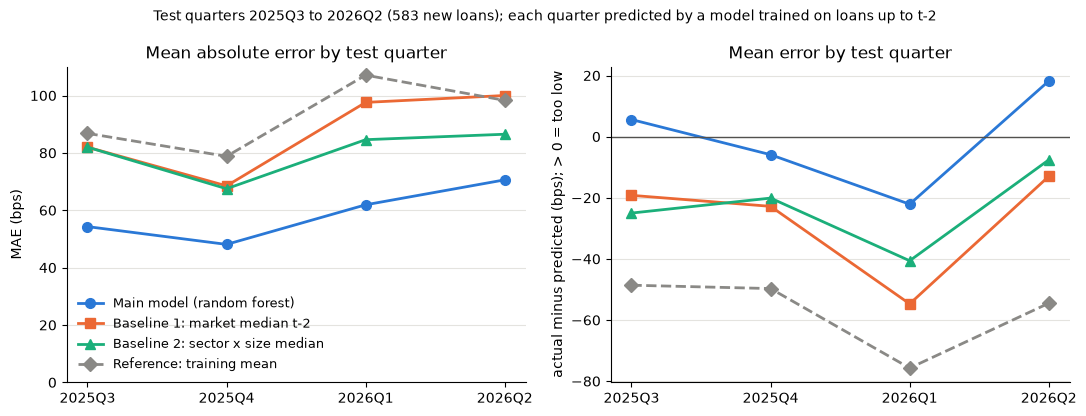

In [5]:
# Figure: two panels with their own y-axis (small multiples, no dual axis); colour follows the candidate.
STYLE = {MAIN: ("#2a78d6", "-", "o", "Main model (random forest)"),
         B1: ("#eb6834", "-", "s", "Baseline 1: market median t-2"),
         B2: ("#1baf7a", "-", "^", "Baseline 2: sector x size median"),
         REF: ("#8a8986", "--", "D", "Reference: training mean")}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(len(QUARTERS))
for m in HEADLINE:
    d = by_q[by_q["model"] == m].set_index("quarter").loc[QUARTERS]
    colour, ls, marker, label = STYLE[m]
    axes[0].plot(x, d["mae_bps"], color=colour, ls=ls, marker=marker, lw=2, ms=7, label=label)
    axes[1].plot(x, d["mean_error_bps"], color=colour, ls=ls, marker=marker, lw=2, ms=7, label=label)
axes[1].axhline(0, color="#52514e", lw=1)
axes[0].set_title("Mean absolute error by test quarter")
axes[0].set_ylabel("MAE (bps)")
axes[0].set_ylim(bottom=0)
axes[1].set_title("Mean error by test quarter")
axes[1].set_ylabel("actual minus predicted (bps); > 0 = too low")
for ax in axes:
    ax.set_xticks(x, QUARTERS)
    ax.grid(axis="y", color="#e4e3df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle(f"Test quarters 2025Q3 to 2026Q2 ({len(test_loans)} new loans); each quarter predicted by a model "
             "trained on loans up to t-2", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "test_by_quarter.png", dpi=150)
plt.show()

# Check
assert (FIG / "test_by_quarter.png").exists()

## Step 4. How certain is the gap to the baselines? (paired bootstrap within quarters)

**What.** The MAE gap main model minus baseline (negative = the model is better) with a 95% interval from a paired
bootstrap: 2,000 times we draw the test loans of each quarter with replacement (same loans for both candidates, the
number of loans per quarter kept), and recompute the gap. We also show the gap in each quarter.

**Why.** 583 loans give one MAE each; a single number does not say whether the gap could be chance. Pairing removes
the noise that is common to both candidates (a hard-to-price loan is hard for both). Drawing within quarters keeps
the mix of quarters fixed. The interval treats loans within a quarter as independent, which they are not entirely
(common market): it is too narrow if anything, so the per-quarter gaps are reported next to it.

**Check.** The point estimate equals the gap of the step-2 table; the interval contains it; 2,000 draws.

In [6]:
N_BOOT = 2000
rng = np.random.default_rng(SEED)
err = test.pivot(index="loan_id", columns="model", values="abs_error_bps").loc[test_loans.index]
quarter_of = test_loans["quarter_str"].to_numpy()

def boot_gap(a, b, n_boot=N_BOOT):
    """Bootstrap draws of mean(a) - mean(b), loans drawn with replacement within each test quarter (paired)."""
    diff = a - b
    sums = np.zeros(n_boot)
    for q in QUARTERS:
        dq = diff[quarter_of == q]
        idx = rng.integers(0, len(dq), size=(n_boot, len(dq)))
        sums += dq[idx].sum(axis=1)
    return sums / len(diff)

rows = []
for base in [B1, B2, REF]:
    a, b = err[MAIN].to_numpy(), err[base].to_numpy()
    draws = boot_gap(a, b)
    row = {"comparison": f"main model minus {base}", "gap_mae_bps": (a - b).mean(),
           "ci95_low_bps": np.percentile(draws, 2.5), "ci95_high_bps": np.percentile(draws, 97.5),
           "share_of_draws_model_better": (draws < 0).mean()}
    for q in QUARTERS:
        row[f"gap_{q}_bps"] = (a - b)[quarter_of == q].mean()
    rows.append(row)
boot = pd.DataFrame(rows).round(1)
boot["share_of_draws_model_better"] = pd.DataFrame(rows)["share_of_draws_model_better"].round(3)
boot.to_csv(TAB / "test_bootstrap.csv", index=False)
print(boot.to_string(index=False))

# Check
h = headline.set_index("model")
for r, base in zip(rows, [B1, B2, REF]):
    assert abs(r["gap_mae_bps"] - (h.loc[MAIN, "test_mae_bps"] - h.loc[base, "test_mae_bps"])) < 0.11
    assert r["ci95_low_bps"] <= r["gap_mae_bps"] <= r["ci95_high_bps"]

                                       comparison  gap_mae_bps  ci95_low_bps  ci95_high_bps  share_of_draws_model_better  gap_2025Q3_bps  gap_2025Q4_bps  gap_2026Q1_bps  gap_2026Q2_bps
   main model minus Baseline 1: market median t-2        -28.2         -33.3          -23.1                          1.0           -27.7           -20.4           -35.7           -29.4
main model minus Baseline 2: sector x size median        -21.8         -26.7          -17.0                          1.0           -27.7           -19.4           -22.7           -15.8
        main model minus Reference: training mean        -34.2         -39.9          -28.4                          1.0           -32.5           -30.7           -45.2           -27.6


## Step 5. Errors by manager family

**What.** Number of test loans, MAE and share within 50 bps of the main model and baseline 1 for each manager
family, sorted by the number of test loans.

**Why.** Committed metric (errors by manager). Apollo and Goldman Sachs alone hold about 30% of the loans; a good
pooled MAE could hide a family the model prices badly. Families with few test loans give noisy MAEs: read those rows
as indications only (the column `n` says how many loans stand behind each number).

**Check.** Loans add up to 583; every family of the test rows appears once.

In [7]:
fam_rows = []
for fam, d in test[test["model"].isin([MAIN, B1])].groupby("family"):
    mm, bb = metrics(d[d["model"] == MAIN]), metrics(d[d["model"] == B1])
    fam_rows.append({"family": fam, "n": int(mm["n"]), "main_mae_bps": mm["mae_bps"],
                     "baseline_1_mae_bps": bb["mae_bps"], "gap_bps": mm["mae_bps"] - bb["mae_bps"],
                     "main_share_within_50bps": mm["share_within_50bps"], "main_mean_error_bps": mm["mean_error_bps"]})
by_fam = (pd.DataFrame(fam_rows).sort_values(["n", "family"], ascending=[False, True])
          .round({"main_mae_bps": 1, "baseline_1_mae_bps": 1, "gap_bps": 1, "main_share_within_50bps": 3,
                  "main_mean_error_bps": 1}))
by_fam.to_csv(TAB / "test_by_family.csv", index=False)
print(by_fam.to_string(index=False))
big = by_fam[by_fam["n"] >= 20]
print(f"\nfamilies with at least 20 test loans: {len(big)} of {len(by_fam)}, holding {big['n'].sum()} loans; "
      f"main model better than baseline 1 in {(big['gap_bps'] < 0).sum()} of them")

# Check
assert by_fam["n"].sum() == 583 and set(by_fam["family"]) == set(test_loans["family"])

                        family  n  main_mae_bps  baseline_1_mae_bps  gap_bps  main_share_within_50bps  main_mean_error_bps
                        Apollo 94          63.7                95.5    -31.8                    0.532                 -7.0
             AllianceBernstein 57          81.6               149.8    -68.2                    0.246                -49.1
                 Goldman Sachs 55          60.5                90.0    -29.5                    0.527                -23.3
                     BlackRock 39          68.2               118.6    -50.4                    0.436                -37.4
                       Antares 35          37.5                44.3     -6.8                    0.714                -12.3
                  Bain Capital 29          30.1                49.5    -19.3                    0.828                  0.3
                     Jefferies 28          42.5                30.4     12.1                    0.714                 17.3
Palmer Square Ca

## Step 6. Every candidate on the test quarters (description only, no choice)

**What.** All 21 candidates of the validation race (models in both rounds, with and without optional features, both
baselines, the reference) with pooled test MAE, share within 50 bps, MAE per test quarter and their validation MAE.

**Why.** Our commitment asks for test MAE overall and by quarter for all models and baselines. The table is
descriptive: the main model stays the one chosen on the validation folds (D49, D51). It also shows whether the
lessons of notebook 02 hold on new quarters (residual target better than the spread as target; trees weak on the
spread as target). The rank on the test quarters is not a reason to change the model: with about 20 candidates,
some will beat the main model on four quarters by chance.

**Check.** 21 candidates (the single-fit variant is in step 7); validation and test rows for each.

In [8]:
cands = [m for m in test["model"].unique() if m != SINGLE]
allc = (test[test["model"].isin(cands)].groupby("model").apply(metrics, include_groups=False)
        [["mae_bps", "share_within_50bps"]].add_prefix("test_"))
per_q = test[test["model"].isin(cands)].pivot_table(index="model", columns="quarter", values="abs_error_bps",
                                                    aggfunc="mean").add_prefix("test_mae_")
val_mae = val.groupby("model")["abs_error_bps"].mean().rename("validation_mae_bps")
allc = allc.join(per_q).join(val_mae)
allc["test_minus_validation_bps"] = allc["test_mae_bps"] - allc["validation_mae_bps"]
allc.insert(0, "is_main_model", allc.index == MAIN)
allc = allc.sort_values("validation_mae_bps").round(1)
allc["test_share_within_50bps"] = (test[test["model"].isin(cands)].groupby("model")["abs_error_bps"]
                                   .apply(lambda e: (e <= 50).mean()).round(3))
allc.reset_index().to_csv(TAB / "test_all_candidates.csv", index=False)
print("sorted by validation MAE (the order in which notebook 02 saw them)")
print(allc.to_string())

# Check
assert len(allc) == 21 and allc["validation_mae_bps"].notna().all() and allc["is_main_model"].sum() == 1

sorted by validation MAE (the order in which notebook 02 saw them)
                                                   is_main_model  test_mae_bps  test_share_within_50bps  test_mae_2025Q3  test_mae_2025Q4  test_mae_2026Q1  test_mae_2026Q2  validation_mae_bps  test_minus_validation_bps
model                                                                                                                                                                                                                     
Random forest (residual, optional features)                False          57.3                    0.563             54.2             45.6             61.5             70.6                54.6                        2.7
Random forest (residual, revolver + delayed draw)           True          58.1                    0.554             54.3             48.1             61.9             70.6                54.9                        3.2
Boosting (residual, optional features)                   

## Step 7. Secondary protocol: the main model fitted once up to 2025Q1

**What.** The main model trained once on all loans up to 2025Q1 and applied to all four test quarters, against the
main protocol (one fit per test quarter on loans up to t-2, D41).

**Why.** D41 keeps one fit as a secondary view. It shows what is lost when a model is not refitted as new filings
come in: the gap to the training data grows from one to four quarters.

**Check.** Same 583 loans in both protocols; in 2025Q3 both protocols use the same training cut (loans up to 2025Q1),
so their predictions must agree there.

In [9]:
pair = test[test["model"].isin([MAIN, SINGLE])]
single = (pair.groupby(["model", "quarter"]).apply(metrics, include_groups=False)["mae_bps"].unstack("quarter"))
single["all"] = pair.groupby("model")["abs_error_bps"].mean()
single = single.loc[[MAIN, SINGLE]].round(1)
single.reset_index().to_csv(TAB / "test_single_fit.csv", index=False)
print(single.to_string())

# Check
p = pair.pivot(index="loan_id", columns="model", values="y_pred")
assert p.notna().all().all() and len(p) == 583
q3 = test_loans.index[test_loans["quarter_str"] == "2025Q3"]
print("largest prediction difference in 2025Q3 (pp):", round((p.loc[q3, MAIN] - p.loc[q3, SINGLE]).abs().max(), 6))
assert np.allclose(p.loc[q3, MAIN], p.loc[q3, SINGLE], atol=1e-4)

quarter                                                                   2025Q3  2025Q4  2026Q1  2026Q2   all
model                                                                                                         
Random forest (residual, revolver + delayed draw)                           54.3    48.1    61.9    70.6  58.1
Random forest (residual, revolver + delayed draw) [single fit to 2025Q1]    54.3    45.0    60.0    72.5  57.2
largest prediction difference in 2025Q3 (pp): 0.0


## Step 8. Sensitivity and robustness

**What.**
1. **Without likely syndicated loans:** the main test sample without loans held by three or more other manager
   families in the same quarter (`n_other_families_same_q >= 3`, D25). The flag uses same-quarter filings, so it
   defines a subsample, never a feature.
2. **All BDCs** (`loans_all_bdc.csv`, model without sector, D45/E7): the main model specification re-fitted in
   notebook 02 on the wider universe, against baseline 1.
3. **Refinancings and add-ons included, tenor from 3 years** (`loans_incl_refi.csv`), against baseline 1.

**Why.** The lecturers asked what the restriction to industry-reporting BDCs implies (feedback 3); the sample
definitions D25 and D35 are judgment calls (README, "Sample definitions"). If the gap to baseline 1 keeps its sign
in these variants, the result does not hinge on them.

**Check.** Subsample size as in `for_modelling.md` for the full file; each robustness file has one prediction per
loan and candidate; the robustness rows are test quarters only.

In [10]:
rob = pd.read_csv(PROC / "predictions_robustness.csv")
synd = test_loans["n_other_families_same_q"] >= 3
keep = test_loans.index[~synd]
print(f"test loans flagged as likely syndicated: {synd.sum()} of {len(test_loans)} ({synd.mean():.0%})")

rows = []
for label, d in [("main sample, all test loans", test),
                 ("main sample without likely syndicated loans", test[test["loan_id"].isin(keep)])]:
    for m in [MAIN, B1, B2]:
        rows.append({"variant": label, "model": m, **metrics(d[d["model"] == m]).to_dict()})
for ds, label in [("loans_all_bdc.csv", "all BDCs (no sector)"),
                  ("loans_incl_refi.csv", "incl. refinancings, add-ons, tenor 3-4 years")]:
    for m in [MAIN, B1]:
        rows.append({"variant": label, "model": m, **metrics(rob[(rob["dataset"] == ds) & (rob["model"] == m)]).to_dict()})
sens = pd.DataFrame(rows)
sens["n"] = sens["n"].astype(int)
sens = sens.round({"mae_bps": 1, "share_within_50bps": 3, "mean_error_bps": 1})
sens.to_csv(TAB / "test_sensitivity_robustness.csv", index=False)
print(sens.to_string(index=False))
gaps = sens[sens["model"].isin([MAIN, B1])].pivot(index="variant", columns="model", values="mae_bps")
print("\ngap main model minus baseline 1 (bps):")
print((gaps[MAIN] - gaps[B1]).round(1).to_string())

# Check
assert not rob.duplicated(["dataset", "model", "loan_id"]).any() and rob["quarter"].isin(QUARTERS).all()
assert (rob.groupby(["dataset", "model"])["loan_id"].nunique()
        == rob.groupby(["dataset", "model"]).size()).all()
assert sens.loc[sens["variant"].str.startswith("main sample without"), "n"].eq(len(keep)).all()

test loans flagged as likely syndicated: 247 of 583 (42%)
                                     variant                                             model    n  mae_bps  share_within_50bps  mean_error_bps
                 main sample, all test loans Random forest (residual, revolver + delayed draw)  583     58.1               0.554            -1.7
                 main sample, all test loans                     Baseline 1: market median t-2  583     86.3               0.503           -27.8
                 main sample, all test loans                  Baseline 2: sector x size median  583     79.9               0.537           -24.0
 main sample without likely syndicated loans Random forest (residual, revolver + delayed draw)  336     55.2               0.592             2.8
 main sample without likely syndicated loans                     Baseline 1: market median t-2  336     79.6               0.533            -5.6
 main sample without likely syndicated loans                  Baseline 2

## Step 9. Summary and final checks

**What.** The headline numbers in one place and a check that every output file was written.

**Interpretation** is in `docs/evaluation_report.md` (counterpart of `docs/model_report.md`), written from the
tables of this notebook; the numbers printed here are the source.

**Check.** All seven tables and the figure exist; the recorded main model is still the one of notebook 02.

In [11]:
h = headline.set_index("model")
b = boot.set_index("comparison").loc[f"main model minus {B1}"]
print(f"main model: test MAE {h.loc[MAIN, 'test_mae_bps']} bps (validation {h.loc[MAIN, 'validation_mae_bps']}), "
      f"{h.loc[MAIN, 'test_share_within_50bps']:.1%} within 50 bps")
print(f"baseline 1: test MAE {h.loc[B1, 'test_mae_bps']} bps, {h.loc[B1, 'test_share_within_50bps']:.1%} within 50 bps")
print(f"gap main minus baseline 1: {b['gap_mae_bps']} bps, 95% interval {b['ci95_low_bps']} to {b['ci95_high_bps']}")

outputs = [TAB / f for f in ["test_headline.csv", "test_by_quarter.csv", "test_bootstrap.csv", "test_by_family.csv",
                             "test_all_candidates.csv", "test_single_fit.csv", "test_sensitivity_robustness.csv"]]
outputs.append(FIG / "test_by_quarter.png")
assert all(p.exists() for p in outputs)
# Check: the main model was not changed after the test evaluation (same record as written by notebook 02)
assert pd.read_csv(TAB / "model_choice.csv").loc[0, "main_model"] == MAIN
print("all outputs written:", len(outputs))

main model: test MAE 58.1 bps (validation 54.9), 55.4% within 50 bps
baseline 1: test MAE 86.3 bps, 50.3% within 50 bps
gap main minus baseline 1: -28.2 bps, 95% interval -33.3 to -23.1
all outputs written: 8
